# DINGO MCMC with fixed center and inclination

This is the same simple three-file R+C model, with **$x_0$, $y_0$, and $i$ held fixed in both the local fit and MCMC**. No earlier fits or candidate search are required. Use the **grism** kernel; restart it before the first run to load the updated functions.

The sampled parameters are $V_\infty$ (km/s), turnover radius (pixels), cutout orientation, and the two R registration offsets (pixels). Intrinsic dispersion is zero. **Velocity intervals are conditional on the chosen fixed geometry; they do not include inclination or center uncertainty.** Fixing geometry is a diagnostic experiment, not a guarantee of a correct velocity.

In [2]:
from pathlib import Path
import os
import sys
import logging
import matplotlib.pyplot as plt
from IPython.display import display

# Change these paths on another computer. No saved fits are read from them.
REPO = Path("/home/aakavan/kinematics/grism-kinematics")
DATA_DIR = REPO / "data"
CALIBRATION_DIR = REPO.parent / "grism_cal"
OUTPUT_ROOT = REPO.parent / "field_kinematics/edr_kinematics/PaA/dingo_runs"

sys.path.insert(0, str(REPO))
os.environ["GRISM_CAL_DIR"] = str(CALIBRATION_DIR)
# Keep warnings visible; progress bars report the sampling steps.
logging.getLogger("dingo.fitting").setLevel(logging.WARNING)
from dingo import simple_mcmc as sm

print("Code:", sm.__file__)
print("Output root:", OUTPUT_ROOT)

Code: /home/aakavan/kinematics/grism-kinematics/dingo/simple_mcmc.py
Output root: /home/aakavan/kinematics/field_kinematics/edr_kinematics/PaA/dingo_runs


## 1. Set the fixed geometry and starting fit

Edit `fixed_x0`, `fixed_y0`, and `fixed_inclination` below. Center coordinates are **absolute, zero-based pixels**: (40, 40) is the geometric center of an 81×81 cutout. This is not automatically a measured galaxy center. Inclination is in degrees; 75° is an editable assumption for this experiment.

The remaining starting values are rounded from the earlier 6170 moderate-velocity fit. They are explicit numbers, not a dependency on saved files. Once center and inclination are fixed to your choices, this is a different conditional fit.

Each source has its own folder under `OUTPUT_ROOT`. Change `run_name` when comparing experiments; `overwrite=True` replaces only that named experiment. Setting any `fixed_*` argument to `None` frees that parameter. If inclination is freed, set `inclination_mean` and `inclination_sigma` explicitly for its Gaussian prior.

ID6170: explicit V_inf=450 km/s; initial i=75 deg; prior i=75 +/- 5 deg.
Saving to /home/aakavan/kinematics/field_kinematics/edr_kinematics/PaA/dingo_runs/6170/fixed_x40_y40_i75_centered_v450
Fixed: x0=40 px, y0=40 px. Excluded from optimization and MCMC; intervals are conditional on these values.
Sampled parameters: ['velocity.V_rot', 'velocity.R_v', 'velocity.theta_v', 'velocity.inc_v', 'image.R.dx', 'image.R.dy']


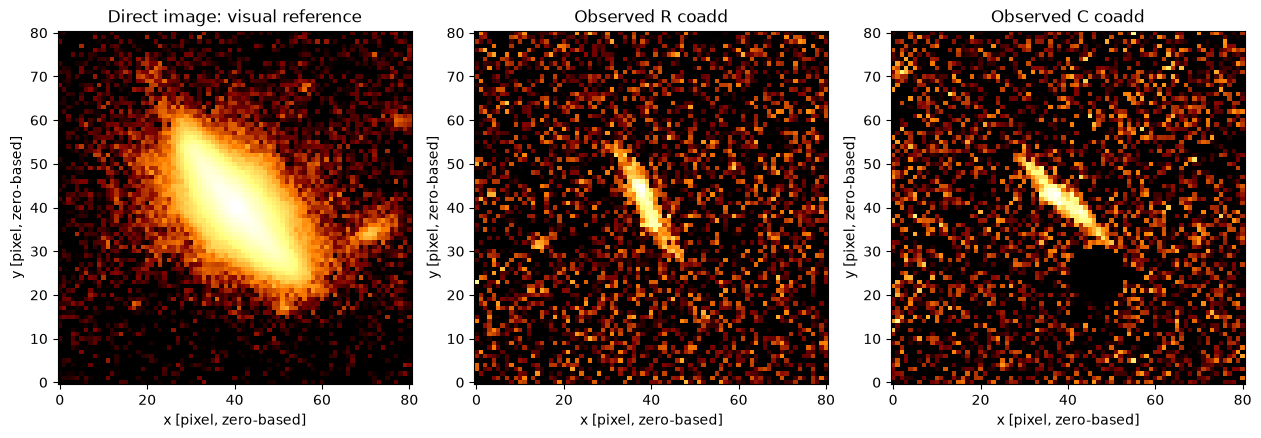

In [11]:
run = sm.prepare(
    6170,
    data_dir=DATA_DIR,
    output_root=OUTPUT_ROOT,
    run_name="fixed_x40_y40_i75_centered_v450",
    overwrite=True,
    device="cuda",                 # or "cpu"

    fixed_x0=40.0,                 # FIXED, pixels
    fixed_y0=40.0,                 # FIXED, pixels
    fixed_inclination=None,        # FIXED, degrees; no Gaussian i prior is used
    start_inclination=75,
    inclination_mean=75,
    inclination_sigma=5.0,           # Gaussian prior width, degrees

    start_velocity=450.0,          # sampled V_inf, km/s
    start_turnover=10.09,          # sampled R_t, pixels
    start_pa=286.64,               # sampled cutout orientation, degrees
    start_offset=(1.0625, 0.2852),  # sampled R registration dx,dy, pixels
    max_velocity=1000.0,
)
print("Sampled parameters:", run.fitter.mcmc_param_names)
fig = sm.show_inputs(run)
display(fig)
plt.close(fig)

## 2. Fit the remaining parameters and inspect residuals

This optional local optimization cannot move the fixed center or inclination. It uses the same posterior as MCMC. The cyan cross marks the fixed kinematic center. Skip `sm.fit_local(...)` to sample directly from the explicit starting values.

Local fit evaluations:   0%|          | 0/3000 [00:00<?, ?it/s]

Local fit: Optimization terminated successfully. (377 evaluations).


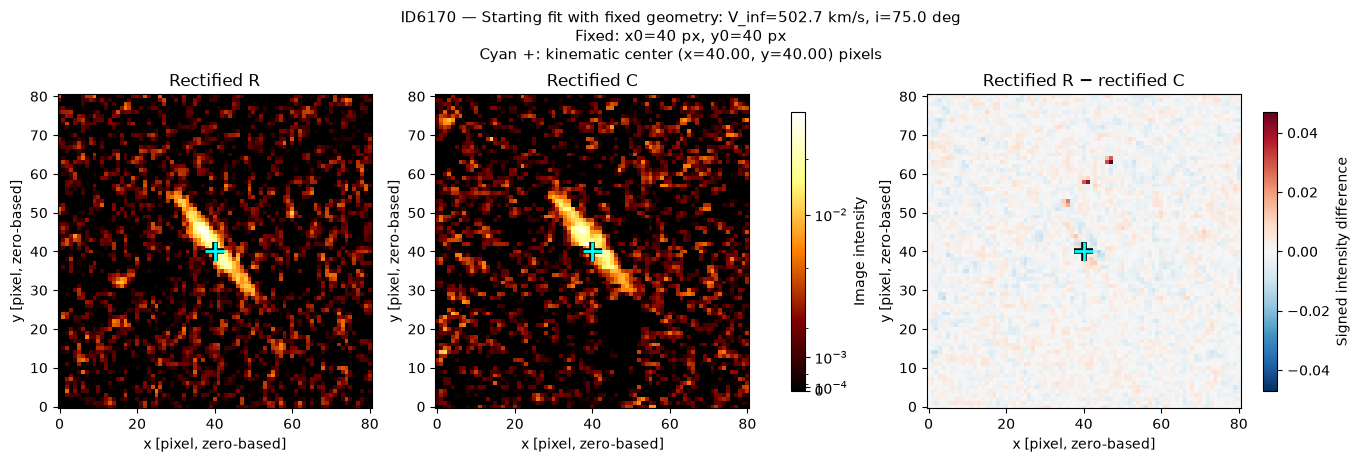

In [12]:
fit_status = sm.fit_local(run, max_evaluations=3000)
fig = sm.show_fit(run, label="Starting fit with fixed geometry")
display(fig)
fig.savefig(run.directory / "starting_fit.png", dpi=150, bbox_inches="tight")
plt.close(fig)

## 3. Run MCMC

Warmup is discarded; draws are retained per walker. For a quick execution check use `warmup=100, draws=200, walkers=32`. Progress and checkpoints work as in the simple notebook. Completion alone does not establish convergence. This uses emcee with the PyTorch likelihood batched on the GPU.

In [13]:
RESULT_DIR = sm.sample(
    run,
    warmup=500,
    draws=1000,
    walkers=64,
    seed=42,
    progress="notebook",           # use True for a text progress bar
)
print(RESULT_DIR)

Warmup:   0%|          | 0/500 [00:00<?, ?it/s]

MCMC draws:   0%|          | 0/1000 [00:00<?, ?it/s]

The chain is shorter than 50 times the integrated autocorrelation time for 6 parameter(s). Use this estimate with caution and run a longer chain!
N/50 = 20;
tau: [25.42367325 26.27981    30.65595633 28.91881609 21.80212862 23.63135002]


finished: 1000 retained steps per walker.
Results: /home/aakavan/kinematics/field_kinematics/edr_kinematics/PaA/dingo_runs/6170/fixed_x40_y40_i75_centered_v450
/home/aakavan/kinematics/field_kinematics/edr_kinematics/PaA/dingo_runs/6170/fixed_x40_y40_i75_centered_v450


## 4. View saved results

The corner plot contains **only sampled parameters**; fixed values are printed in its title and saved in `run_info.txt` and the NPZ files. The table gives pooled median and 16–84% intervals. Residuals use one actual maximum-posterior sample.

To reopen results after restarting, run the imports and this cell with `RESULT_DIR` set below. Do not rerun preparation with `overwrite=True` merely to view results.

Status: finished; retained steps/walker: 1000; latest segment mean acceptance: 0.182
These are conditional posterior summaries. Check traces, bounds and independent starts before quoting errors.
Fixed: x0=40 px, y0=40 px. These quantities were not sampled; their uncertainty is not included.
Autocorrelation time per parameter: {'velocity.V_rot': 25.423673253718654, 'velocity.R_v': 26.279810003500707, 'velocity.theta_v': 30.65595633485992, 'velocity.inc_v': 28.91881608594965, 'image.R.dx': 21.80212861648408, 'image.R.dy': 23.631350016186566}


,median,minus_16th,plus_84th,unit
parameter (all walkers pooled),,,,
V_inf,903.807045,43.852427,45.421823,km/s
R_t,28.457349,1.783478,1.797718,pixel
cutout_PA,295.779466,0.442359,0.384637,deg
inclination,76.118967,0.869586,0.824970,deg
R_x_offset,1.439141,0.047499,0.043998,pixel
R_y_offset,0.283043,0.016245,0.015635,pixel


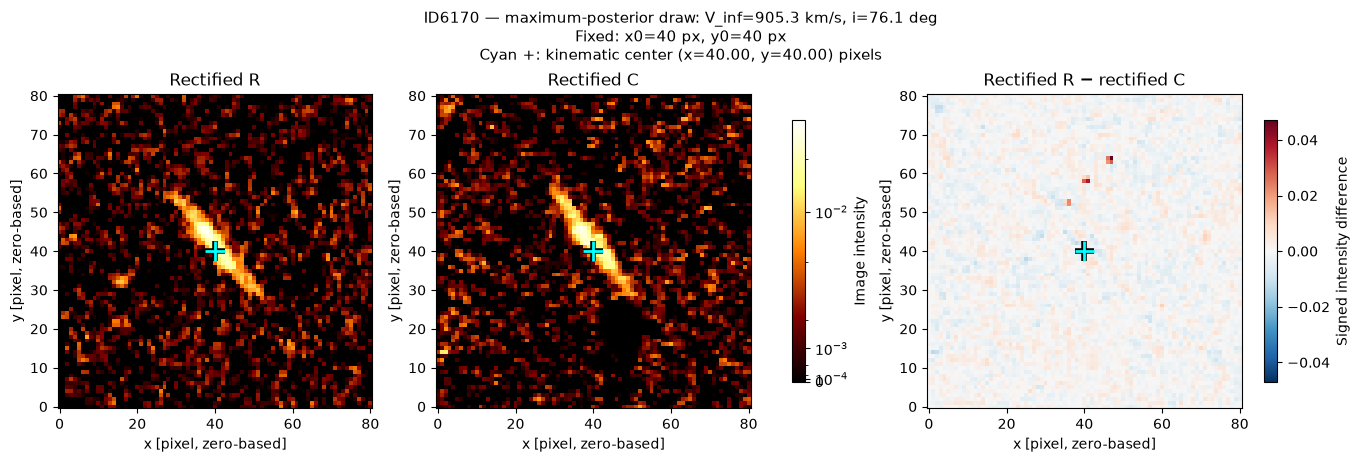

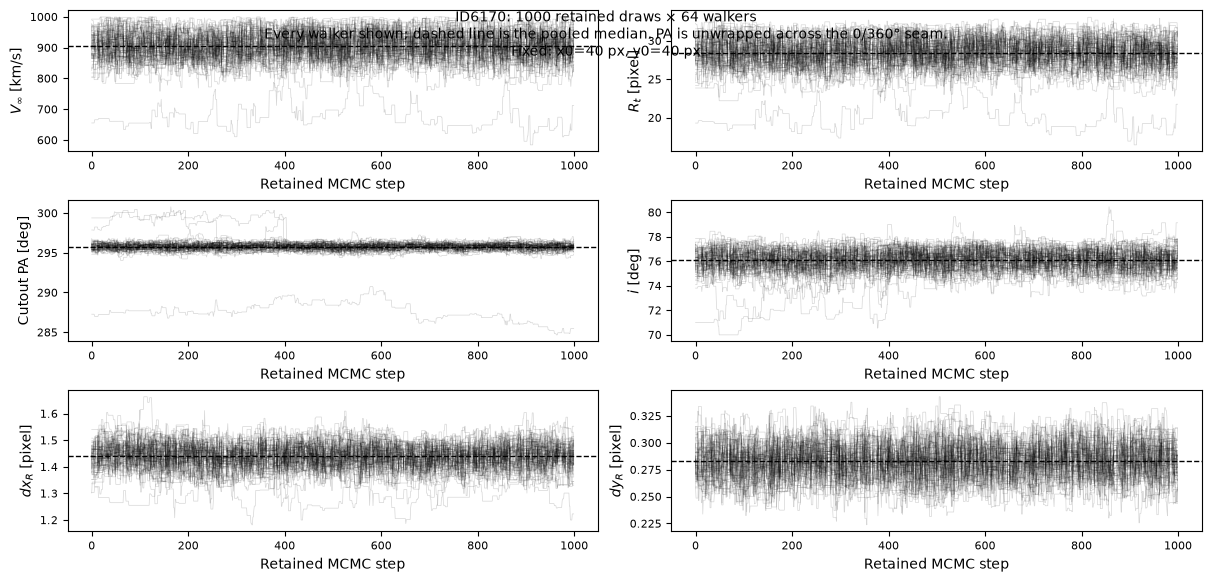

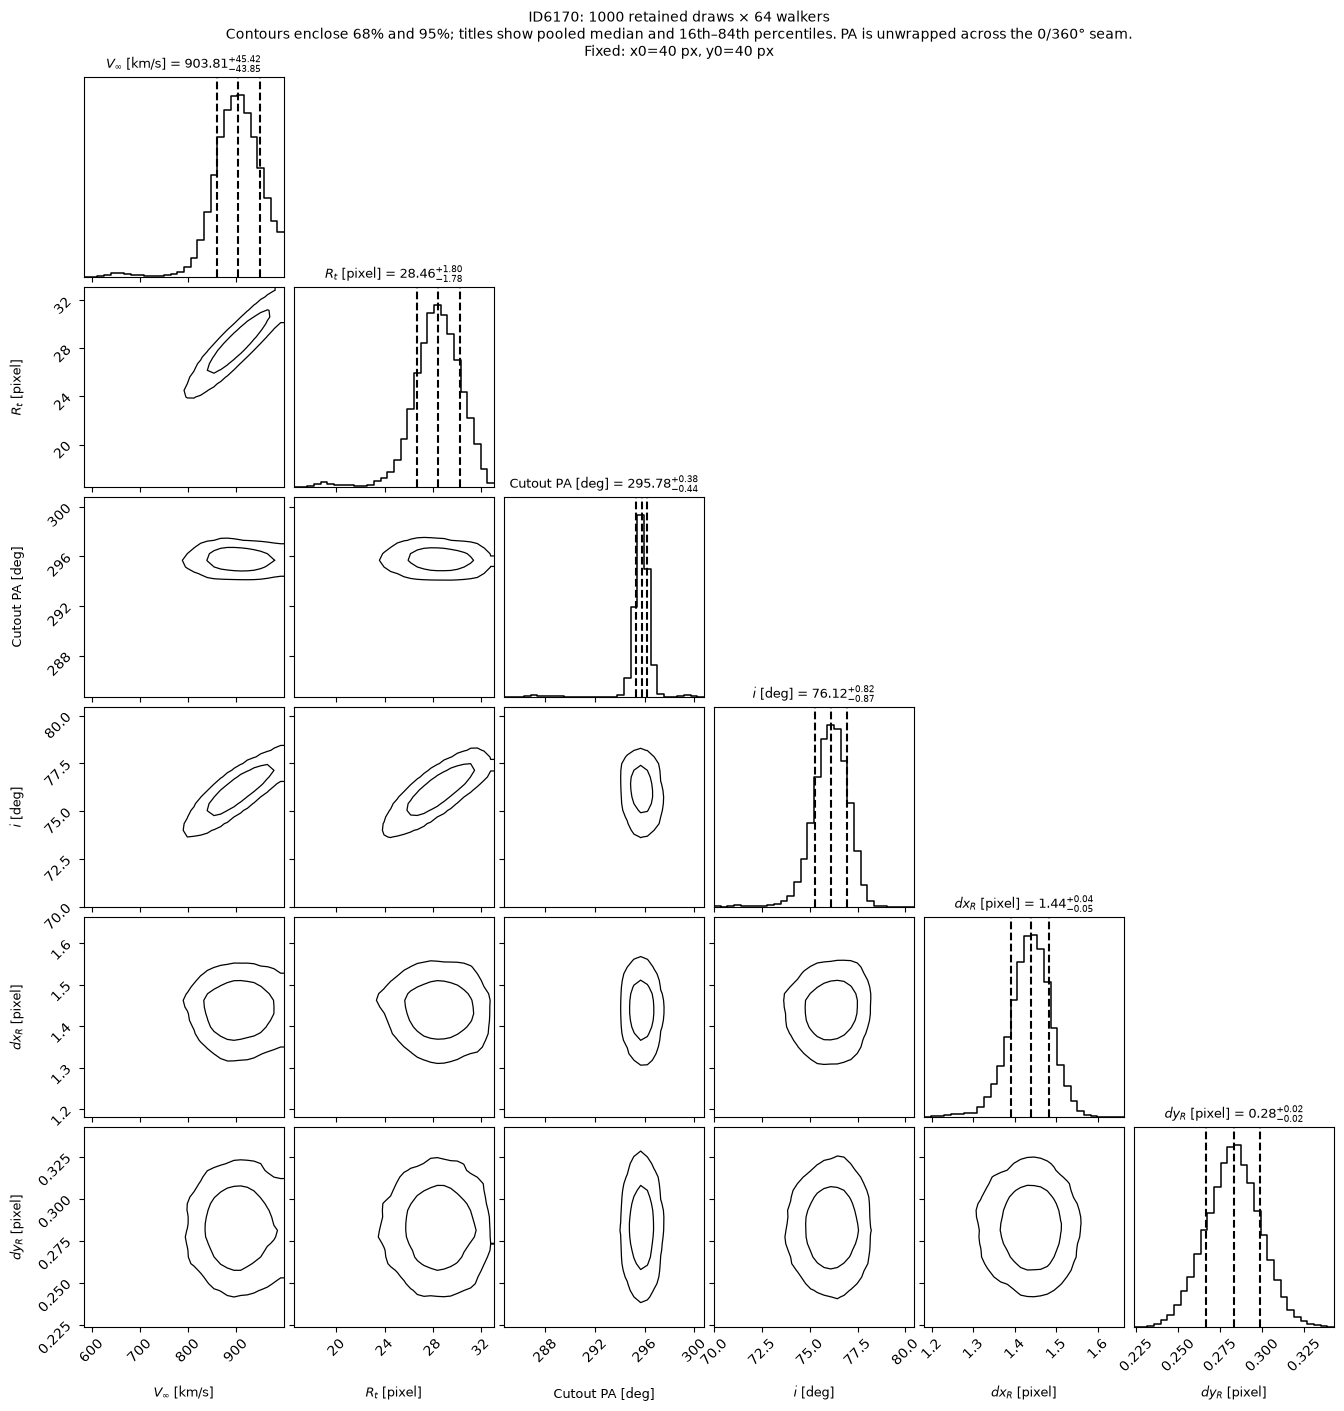

In [14]:
# To open saved results without fitting:
# RESULT_DIR = OUTPUT_ROOT / "6170" / "fixed_x40_y40_i75_v450"
views = sm.show_results(RESULT_DIR)
display(views["summary"])
for name in ("residuals", "traces", "corner"):
    display(views[name])
    plt.close(views[name])

The likelihood is the original full-image squared corrected R−C residual divided by a fixed noise variance estimated from the input stacks. This does not fully propagate coadd/interpolation covariance. The remaining priors are uniform $V_\infty$ from 0 to `max_velocity`, log-uniform turnover radius from 0.5 pixels to the cutout half-width, full-turn uniform orientation, and Gaussian R registration offsets about zero with width 2 pixels (truncated at ±10). Fixed center/inclination priors are removed.

A velocity piling up at its bound is still not a measured plateau speed. Inspect residuals, traces and independent starting points before quoting uncertainties.

Results are saved in `OUTPUT_ROOT/source_ID/run_name/`. To resume after a kernel restart: `run = sm.open_run(saved_directory)`, then `sm.sample(run, warmup=1000, draws=4000, walkers=64, resume=True, progress="notebook")`, preserving the original warmup and walker count. To change fixed geometry, prepare a different named experiment.

## 5. Convert the saved run to physical units

**These new blocks only read the saved posterior; they do not run optimization or MCMC.** `RESULT_DIR` is the folder selected above. After a kernel restart, set it to the saved run you want before using these blocks.

Redshift is read from this run's saved source metadata. We use **Planck18 angular-diameter distances**, giving proper pc per arcsecond. The R/C FITS cutouts do not contain a pixel scale, so declare the scale of the **R/C stacks**, not the SW imaging used by PySersic. The current native LW cutouts use the adopted value **0.063 arcsec/pixel**. Change it for resampled data.

$$R_t[\mathrm{pc}]=R_t[\mathrm{pixel}]\,s[\mathrm{arcsec/pixel}]\,\mathrm{scale}(z)[\mathrm{pc/arcsec}].$$

Redshift, cosmology and pixel scale are treated as fixed. No lensing correction is applied.

In [15]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from dingo.simple_mcmc_profiles import PhysicalProfiles

# If reopening saved results, set this to your run folder:
# RESULT_DIR = Path("/home/aakavan/kinematics/field_kinematics/edr_kinematics/PaA/dingo_runs/6170/fixed_x40_y40_i75_v450")
PIXEL_SCALE_ARCSEC = 0.063  # R/C stack scale; do not substitute the F150W imaging scale
physical = PhysicalProfiles(RESULT_DIR, pixel_scale_arcsec=PIXEL_SCALE_ARCSEC)
print(f"ID{physical.source_id}: z = {physical.scale['redshift']:g}; {physical.scale['cosmology']}")
print(f"1 arcsec = {physical.scale['pc_per_arcsec']:,.2f} pc")
print(f"1 R/C pixel = {physical.scale['pc_per_pixel']:,.2f} pc")
print("Reading saved results from:", RESULT_DIR)

ID6170: z = 1.1147; Planck18
1 arcsec = 8,416.91 pc
1 R/C pixel = 530.27 pc
Reading saved results from: /home/aakavan/kinematics/field_kinematics/edr_kinematics/PaA/dingo_runs/6170/fixed_x40_y40_i75_centered_v450


## 6. Velocity at the turnover radius, and turnover radius in parsecs

For this arctangent model, **$V(R_t)=V_\infty/2$ exactly**. We compute that velocity and $R_t$ in pc separately for every posterior draw, then report the pooled median and 16th–84th percentile offsets. The velocity is evaluated at **each draw's own turnover radius**, not at the median turnover radius.

The turnover radius may lie outside the well-measured emission. These are conditional model quantities; fixing the geometry excludes its uncertainty.

In [16]:
turnover = physical.turnover_summary(save=True)
display(turnover)

,median,minus_16th,plus_84th,unit
parameter,,,,
turnover_velocity,451.903523,21.926214,22.710912,km/s
turnover_radius_pixels,28.457349,1.783478,1.797718,pixel
turnover_radius_pc,15089.952036,945.716947,953.267841,pc


## 7. Rotation curve in physical units

At each common radius, evaluate every paired $(V_\infty,R_t)$ posterior draw before taking percentiles. This preserves their correlation; it is different from inserting two marginal medians into the equation.

The line is the median, the band is the **pointwise 16th–84th percentile interval**, and the vertical marker is the median turnover radius when it falls within the displayed range. `MAX_RADIUS_PIXELS` sets a plotting range, **not a measured emission boundary**; the outer curve can be extrapolated. All velocities are already deprojected.

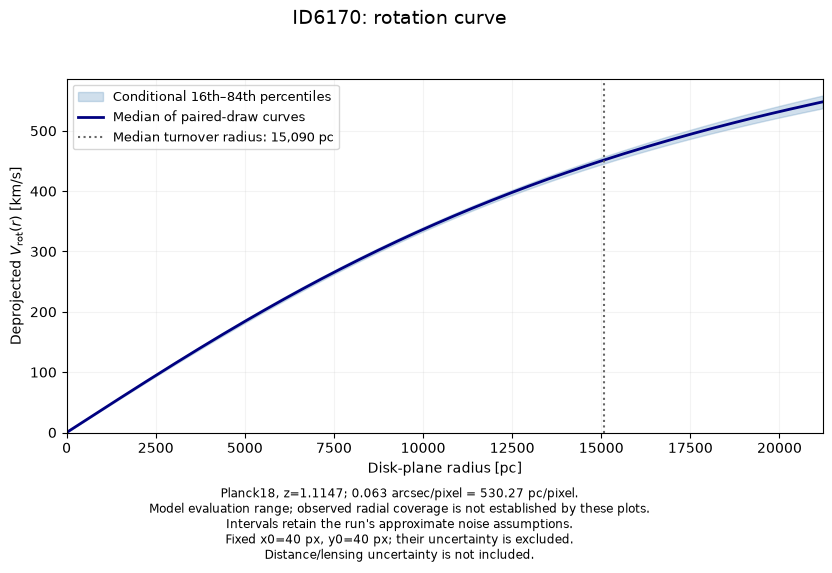

In [17]:
MAX_RADIUS_PIXELS = 40.0  # Display range only; adjust after assessing emission coverage
radii_pc = np.linspace(0.0, MAX_RADIUS_PIXELS * physical.scale["pc_per_pixel"], 161)
fig = physical.rotation_curve(radii_pc, save=True)
display(fig)
plt.close(fig)

## 8. Enclosed dynamical-mass estimate

Use the rotation speed **at each radius**, rather than inserting $V_\infty$ everywhere:

$$M_{\mathrm{dyn,sph}}(<r)=\frac{r\,V_{\mathrm{rot}}(r)^2}{G}.$$

This is a **rotation-only, spherical-equivalent enclosed-mass estimate**: it assumes rotation traces circular support and uses the spherical conversion from speed to enclosed mass. It includes no pressure-support, disk-geometry, or lensing correction. We calculate it for every posterior draw before taking percentiles. The band includes the sampled kinematic uncertainty, but not uncertainty in the fixed center, inclination, redshift or pixel scale.

The outer mass curve is also extrapolated wherever the emission does not constrain the rotation curve. The new plots, turnover table and `physical_profiles.npz` are saved in the same run folder; existing samples and fit settings are unchanged.

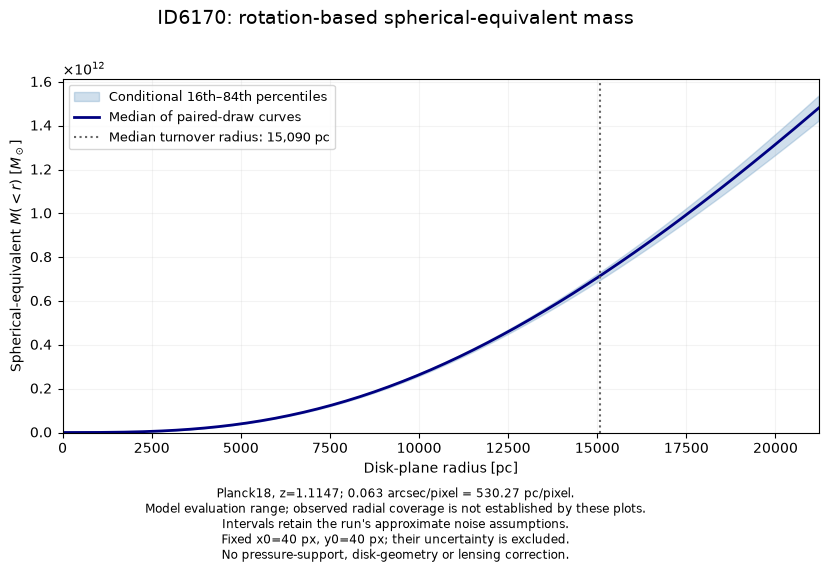

Saved turnover summary, rotation curve, dynamical mass, and physical_profiles.npz to: /home/aakavan/kinematics/field_kinematics/edr_kinematics/PaA/dingo_runs/6170/fixed_x40_y40_i75_centered_v450


In [18]:
fig = physical.mass_profile(radii_pc, save=True)
display(fig)
plt.close(fig)
print("Saved turnover summary, rotation curve, dynamical mass, and physical_profiles.npz to:", RESULT_DIR)